## Yamini Sirobushanam, Livi Gallagher, Zoe Scherrer

# Case 1: Screening a Consumer Auto-Loan Pricing Model

**Your role:** analyst candidate on a consumer-finance team  
**Decision maker:** head of auto-loan pricing  
**Data:** `case01_auto_loan_apr_lab.csv`, 603 raw application records

## Brief

The current rule of thumb lowers the quoted APR by 1 percentage point for every 25 points of FICO. The pricing head suspects that this overstates how much APR should move when FICO rises. You receive a raw export with missing values, duplicate application IDs, invalid codes, one obvious APR extraction error, and one economically unusual but potentially legitimate loan. Management wants a defensible descriptive model, not a causal claim about changing a person's score.

**Management question:** How strongly is an applicant's credit score associated with the APR quoted by the lender, and is the relationship useful as a first-pass pricing screen?

## Data dictionary

| Variable | Units or type | Meaning |
|---|---|---|
| `application_id` | Identifier | Unique application record. Duplicates are possible in the raw export. |
| `fico_score` | Points | Credit score. The valid range is 300 to 850; values outside it are invalid codes. Some values are missing. |
| `loan_amount_usd` | US dollars | Requested principal. Available for descriptive checks but not part of the baseline model. |
| `apr_pct` | Percentage points | Quoted annual percentage rate. Values above 36 are extraction errors. Some values are missing. |
| `source_batch` | Category | Extraction batch A, B, or C. |

## Submission

- Before you submit, restart the kernel and run all cells. The notebook must run from top to bottom without errors.
- Submit the notebook twice: the .ipynb file and a PDF export with all code and output readable.

In [1]:
# Starter code: run this cell first and do not edit it.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# The raw export, exactly as received. Leave raw unchanged and build your analysis sample from it.
raw = pd.read_csv('case01_auto_loan_apr_lab.csv')
raw.head()

,application_id,fico_score,loan_amount_usd,apr_pct,source_batch
0,AL100000,644.0,14080.52,8.633,C
1,AL100001,618.0,16914.08,10.524,C
2,AL100002,721.0,33785.22,5.614,C
3,AL100003,728.0,18802.21,8.626,A
4,AL100004,700.0,15159.19,7.118,B


In [2]:
raw.shape

(603, 5)

## Stage 1. Frame the business question

State the decision the model will inform. Separate a descriptive pricing relationship from a causal effect of credit score.

**Output:** a two-sentence estimand statement.

Our estimand is the relationship between FICO scores and the quoted APR to evaluate whether the FICO score is a useful predictor of such. This is not a causal relationship, as it describes how the two vary together. 

## Stage 2. Audit the raw file

Check for duplicate IDs, missing values, and values outside the valid ranges in the data dictionary. Apply the rules in this order: duplicate IDs, missing values, FICO range, APR range. When an `application_id` appears more than once, keep its first record and remove the later ones. Record how many records each rule removes. Remove a record that breaks a rule; do not correct its value. Do not remove a record just because its values look unusual. Store your analysis sample as `df`.

**Output:** a cleaning log and the final sample size.

In [3]:
raw.duplicated().sum()

np.int64(3)

In [4]:
raw[raw.duplicated(keep=False)]
#3 duplicate rows

,application_id,fico_score,loan_amount_usd,apr_pct,source_batch
41,AL100041,710.0,28277.26,8.450,A
218,AL100218,624.0,33787.29,10.318,A
503,AL100503,749.0,18786.75,5.645,A
600,AL100041,710.0,28277.26,8.450,A
601,AL100218,624.0,33787.29,10.318,A
602,AL100503,749.0,18786.75,5.645,A


In [5]:
#Duplicate ID
df = raw.copy()
df = df.drop_duplicates(subset = 'application_id', keep = 'first')

In [6]:
df.shape

(600, 5)

In [7]:
#missing values
df = df.dropna()
df.isna().sum()

application_id     0
fico_score         0
loan_amount_usd    0
apr_pct            0
source_batch       0
dtype: int64

In [8]:
df.shape

(591, 5)

In [9]:
#FICO Range: 591 observations pre cleaning
df['fico_score'].describe()


count    591.000000
mean     688.834179
std       53.897136
min      528.000000
25%      651.000000
50%      691.000000
75%      725.000000
max      999.000000
Name: fico_score, dtype: float64

In [10]:
df = df[(df['fico_score'] >= 300) & (df['fico_score'] <= 850)]

In [11]:
df['fico_score'].min()
df['fico_score'].max()

print(df['fico_score'].min(), df['fico_score'].max())

528.0 835.0


In [12]:
#APR Range: 588 observations pre cleaning
df['apr_pct'].describe()

count    589.000000
mean       8.524857
std        3.841051
min        2.770000
25%        6.834000
50%        8.404000
75%        9.870000
max       86.000000
Name: apr_pct, dtype: float64

In [13]:
df = df[(df['apr_pct'] >= 0) & (df['apr_pct'] <= 36)]

In [14]:
df.describe()
#Pre Cleaning: FICO_score had 591 observations & now it has 588 observations
#Pre Cleaning: apr_pct had 588 observations & still has 588 observations


,fico_score,loan_amount_usd,apr_pct
count,588.000000,588.000000,588.000000
mean,687.792517,26564.720476,8.393097
std,50.899686,11322.004751,2.129758
min,528.000000,5521.830000,2.770000
25%,651.000000,18424.035000,6.830750
50%,691.000000,24790.375000,8.398000
75%,725.000000,32294.860000,9.866250
max,835.000000,75000.000000,21.374000


In [15]:
df['apr_pct'].min()
df['apr_pct'].max()

print(df['apr_pct'].min(), df['apr_pct'].max())

2.77 21.374


In [16]:
df.shape

(588, 5)

In [17]:
#Cleaning Log 
df

,application_id,fico_score,loan_amount_usd,apr_pct,source_batch
0,AL100000,644.0,14080.52,8.633,C
1,AL100001,618.0,16914.08,10.524,C
2,AL100002,721.0,33785.22,5.614,C
3,AL100003,728.0,18802.21,8.626,A
4,AL100004,700.0,15159.19,7.118,B
...,...,...,...,...,...
595,AL100595,747.0,28148.78,6.070,B
596,AL100596,687.0,48114.91,9.696,B
597,AL100597,771.0,19042.15,4.866,B
598,AL100598,725.0,30767.36,7.477,B


## Stage 3. Characterize the data

Report summary statistics for your analysis sample and a scatterplot of APR against FICO.

**Output:** one table and one figure.

In [18]:
#Summary Stats
df.describe()

,fico_score,loan_amount_usd,apr_pct
count,588.000000,588.000000,588.000000
mean,687.792517,26564.720476,8.393097
std,50.899686,11322.004751,2.129758
min,528.000000,5521.830000,2.770000
25%,651.000000,18424.035000,6.830750
50%,691.000000,24790.375000,8.398000
75%,725.000000,32294.860000,9.866250
max,835.000000,75000.000000,21.374000


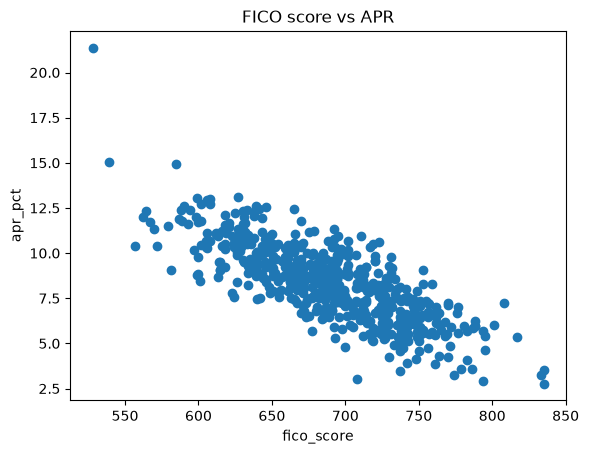

In [19]:
plt.scatter(df['fico_score'],df['apr_pct'])
plt.xlabel('fico_score')
plt.ylabel('apr_pct')
plt.title("FICO score vs APR")
plt.show()

## Stage 4. Specify the model

The simple regression model is $y_i = \beta_0 + \beta_1 x_i + u_i$. Write it for this case: say which variable is $y$ and which is $x$, and why. Define the units of $\beta_1$ and predict its sign before estimating.

**Output:** a model statement.

APR PCT = $\beta_0$ + FICO SCORE  $x_i$ + $u_i$

Y is APR % and x is FICO score because we are evaluating whether FICO is useful as a first-pass pricing screen in determining the APR quoted by the lender. As beta increases by 1 FICO point, we can expect APR percentage to decrease, as the scatterplot shows a negative association. As FICO_score increases, apr_pct decreases.


## Stage 5. Estimate the baseline

Estimate the model by OLS on your analysis sample and store the fitted model as `fit`. Report n, the intercept, the slope, the slope's standard error and 95% confidence interval, R-squared, and the residual RMSE, the square root of the mean squared residual.

**Output:** a compact regression table.

In [20]:
fit = smf.ols('apr_pct ~ fico_score', data=df).fit()

In [21]:
print(fit.summary())

                            OLS Regression Results                            
Dep. Variable:                apr_pct   R-squared:                       0.622
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     966.0
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          4.80e-126
Time:                        19:43:07   Log-Likelihood:                -992.01
No. Observations:                 588   AIC:                             1988.
Df Residuals:                     586   BIC:                             1997.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     31.0979      0.733     42.454      0.0

In [22]:
#RMSE
np.sqrt(np.mean(fit.resid**2))

np.float64(1.3075575299032245)

NP: 588

Intercept: 31.1

Slope = -0.033

Slope SE & CI:  0.001 & [-0.035, -0.031] 

R-squared : 0.622

Residual RSME: 1.31

## Stage 6. Check the assumptions relevant at this point

Answer each in one or two sentences.

- Is a straight line a reasonable description of how APR moves with FICO? Use a plot of the residuals against FICO.
- Is there enough spread in FICO to estimate the slope?
- Each `application_id` is one application. If the same application appears twice, what is true of the errors of the two copies, and what does keeping both do to how much information OLS thinks it has? (This is the assumption that the errors of different observations are uncorrelated, not the assumption that the error is unrelated to FICO.)

**Output:** an assumption checklist.

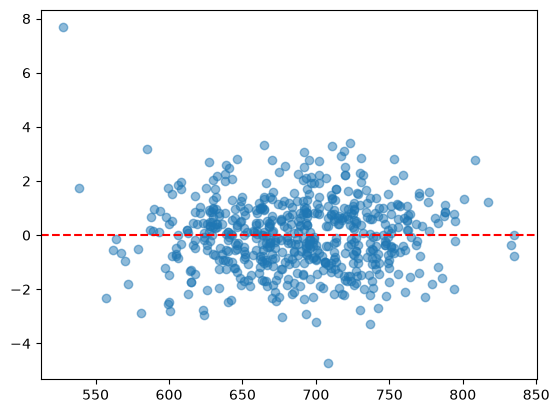

In [23]:
# Number 1
plt.scatter(df["fico_score"], fit.resid, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")

A straight line is a reasonable description of how APR moves with FICO. Majority of the data points are crowding around the center, with no visible pattern

In [24]:
#Number 2
print(f"FICO Range: {df['fico_score'].min()} to {df['fico_score'].max()}")
print(f"FICO Std Dev: {df['fico_score'].std():.2f}")


FICO Range: 528.0 to 835.0
FICO Std Dev: 50.90


FICO score ranges from 528 to 835, with a standard deviation of 50.90. There is enough variation in the sample. 

In [25]:
#Number 3: Verifying that there are no duplicates
duplicate_count = df.duplicated(subset=["application_id"]).sum()
print(f"Number of duplicate application rows: {duplicate_count}")

Number of duplicate application rows: 0


Typically having more observations will reduce the overall standard error. If two application id's appear twice in the sample, then they will both have the same underlying error and OLS will assume they are independent observations. The overall standard error could potentially be underestimated.  

### Stage 7. Diagnose influential observations

Use an influence measure to find the most influential loan in your analysis sample.
Show where it sits on a residual plot.
Is there evidence that it is a data error, or does it look like a legitimate, if unusual, loan? 
Explain what in the data supports your answer.
Should it stay in your analysis sample?
Output: a diagnostic note and a decision on the analysis sample.

In [26]:
# Given code: run this cell as it is. It needs fit from Stage 5.
# One row per loan in your model, labelled with df's row labels, with its influence measures,
# for example Cook's distance (cooks_d), hat values (hat_diag) and studentized residuals (student_resid).
# This cell shows nothing; look at measures in the next cell.
measures = fit.get_influence().summary_frame()
measures.head()

,dfb_Intercept,dfb_fico_score,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
0,-0.035501,0.032783,0.001262,-0.921924,0.002962,-0.050247,-0.921806,-0.050241
1,-0.007890,0.007507,0.000043,-0.132425,0.004904,-0.009296,-0.132314,-0.009288
2,0.030688,-0.034702,0.002012,-1.286413,0.002426,-0.063436,-1.287134,-0.063471
3,-0.035219,0.038959,0.001972,1.192832,0.002764,0.062795,1.193263,0.062818
4,0.004554,-0.006600,0.000400,-0.666445,0.001799,-0.028290,-0.666128,-0.028276


In [27]:
measures.sort_values('cooks_d', ascending=False)[['cooks_d', 'hat_diag', 'student_resid']].head()

,cooks_d,hat_diag,student_resid
117,0.332187,0.018490,6.120504
119,0.026032,0.011202,2.150365
502,0.025800,0.008649,2.442292
506,0.022348,0.009200,-2.201193
40,0.021133,0.012949,-1.798342


Row 117 ranks highest amongst all 3 influence measures. It is the most influential loan in our analysis sample

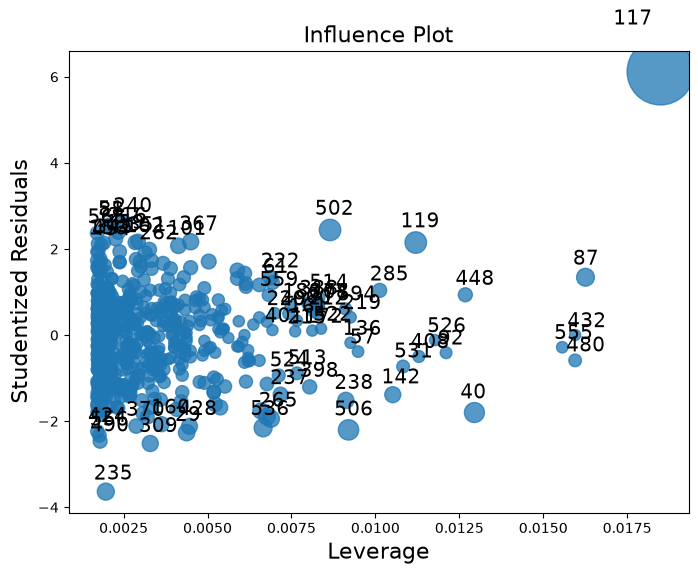

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))
sm.graphics.influence_plot(fit, criterion='cooks', ax=ax)
plt.show()
#The 117 in the corner legitimizes the fact that it is the most influential 

In [29]:
df.loc[117]

application_id     AL100117
fico_score            528.0
loan_amount_usd    32016.67
apr_pct              21.374
source_batch              C
Name: 117, dtype: object

Observation 117 is unusual but legitimate based on Cook's distance. The observation's cook distance value is equal to 0.3322, the highest in the sample, which implies the most influence. The fico, apr and loan value also fall within an acceptable range, therefore there is no data entry error.Given that Cook's distance is < 1, removal is not automatically warranted, therefore I would keep the observation within the sample as of now. 

### Stage 8. Re-estimate and compare

Whatever you decided in Stage 7, re-estimate the model without that loan.

* Store the smaller sample as df_without_loan and its fit as fit_without_loan. Leave df and fit as they are.
* Show the intercept and slope from the two fits side by side.
* Redo your Stage 6 residual plot using df_without_loan and fit_without_loan. Is a straight line still a reasonable description of how APR moves with FICO?

Output: a coefficient comparison and a second residual plot.

In [30]:
#removing loan 117
df_without_loan = df.drop(index=117)

fit_without_loan = smf.ols('apr_pct ~ fico_score', data=df_without_loan).fit()

In [31]:
#comparing coefficients: 
pd.DataFrame({'Original': fit.params,'Without Loan 117': fit_without_loan.params})

,Original,Without Loan 117
Intercept,31.097860,30.517121
fico_score,-0.033011,-0.032186


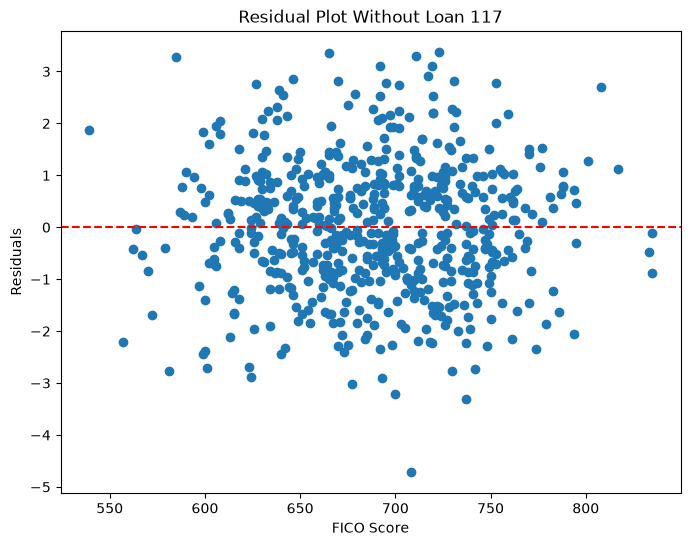

In [32]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(df_without_loan['fico_score'], fit_without_loan.resid)
ax.axhline(0, color='red', linestyle='--')

ax.set_xlabel('FICO Score')
ax.set_ylabel('Residuals')
ax.set_title('Residual Plot Without Loan 117')

plt.show()


Removing loan 117 resulted in only minor changes to the intercept and slope, suggesting the observation does not substantially influence the estimated relationship between FICO score and APR. A linear fit is still reasonable

In [33]:
print(fit_without_loan.summary())

#Results: The FICO score and apr barely change when you remove 117
#

                            OLS Regression Results                            
Dep. Variable:                apr_pct   R-squared:                       0.621
Model:                            OLS   Adj. R-squared:                  0.620
Method:                 Least Squares   F-statistic:                     959.1
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          2.13e-125
Time:                        19:43:07   Log-Likelihood:                -972.61
No. Observations:                 587   AIC:                             1949.
Df Residuals:                     585   BIC:                             1958.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     30.5171      0.717     42.560      0.0

### Stage 9. Interpret the estimate

The current rule of thumb lowers APR by 1 percentage point (a difference of -1) for every 25-point rise in FICO score. Use the fit for the sample you chose in Stage 7: fit if you kept the loan, fit_without_loan if you dropped it.

Your slope is in percentage points of APR per FICO point. Translate it into the predicted APR difference, in percentage points, for a 25-point FICO increase.
Do the same for the slope's 95% confidence interval.
Using that interval, is the rule of thumb consistent with your estimate?
What does your R-squared tell you about your model, and what does it not tell you?
Output: an economic interpretation.

In [34]:
#Keeping the loan
#Predicted apr score for ever 25 point increase - interpreting it from 1 unit change to 25 unit change
fit.params['fico_score'] * 25

np.float64(-0.8252766084840004)

In [35]:
#95% confidence interval
fit.conf_int().loc['fico_score'] * 25

0   -0.877426
1   -0.773127
Name: fico_score, dtype: float64

In [36]:
fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                apr_pct   R-squared:                       0.622
Model:                            OLS   Adj. R-squared:                  0.622
Method:                 Least Squares   F-statistic:                     966.0
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          4.80e-126
Time:                        19:43:07   Log-Likelihood:                -992.01
No. Observations:                 588   AIC:                             1988.
Df Residuals:                     586   BIC:                             1997.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     31.0979      0.733     42.454      0.000      29.659      32.537
fico_score    -0.0330      0.001    -31.081      0.000      -0.035      -0.031
==============================================================================
Omnibus:                       35.902   Durbin-Watson:                   2.088
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               83.327
Skew:                           0.321   Prob(JB):                     8.05e-19
Kurtosis:                       4.729   Cond. No.                     9.35e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 9.35e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

A 25 point increase in FICO score is associated with a decrease in APR of appriximately 0.825 percetnage points. The 95% confidence interval is approximately [-0.877426, -0.773127]. This is not consistent because the interval increases by 1 unit. 

The R^2 values of 0.622 indicates that 62.2% of the variation in APR is explained by FICO score. It does not tell us if there is a direct causation between the two variables. 

### Stage 10. Assess causality

The slope is the causal effect of FICO only if everything else that affects APR is unrelated to FICO (zero conditional mean).

Name two things, other than the variables in the data, that affect a quoted APR and are likely related to FICO.
What does that mean for reading the slope as the effect of raising someone's score?
Output: a causal-claim verdict.

Two things that affect a quoted APR could be the applicant's employment history and even socioeconomic factors, like gender. Higher FICO scores likely have job stability which could reduce the risk and lower quoted APR. Socioeconomic factors like gender related differences in income, could do the opposite.
We cannot interpret the slope as a causal effect. Raising FICO scores do not directly translate to lowering APR as there are other outside factors affecting these estimates. 

### Stage 11. Recommendation to the head of auto-loan pricing

In one paragraph of about 150 words, cover:

how much APR moves with FICO, with a likely range;
whether the current rule of thumb should change;
the limitation you think matters most;
how the model should be used.
Write for a manager who has not taken econometrics: say what the numbers mean for pricing, in plain words.

Output: the recommendation.

A 25 point increase in FICO score is associated with an estimated decrease in APR of 0.825 percentage points, with a likely range of [-0.877426, -0.773127]. I would not recommend changing the current rule of thumb. While our estimate is different, there are liekly other important variables that are not included in our regression, skewing out results. The limitation here are our two predictors, we likely have omitted variable bias because we're leaving some important variables out. This model can be used to describe the relationship between FICO and APR but it cannot estimate the true (causal) effect between the two. 